In [1]:
import re
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)


@dataclass(frozen=True)
class Config:
    data_file: str = "data parasetamol jurnal.xlsx"
    verified_file: str = "data_terverifikasi.xlsx"
    output_dir: str = "outputs"
    seed: int = 20261127
    n_time: int = 20
    run_length: int = 10
    simulations: int = 500
    blocks: tuple = (5, 10)
    sbp_corrections: tuple = ((1113, 113), (1114, 114))
    draws: int = 200_000
    first_data_row: int = 5


CFG = Config()
RNG = np.random.default_rng(CFG.seed)
OUT = Path(CFG.output_dir)
OUT.mkdir(exist_ok=True)
VITALS = {"sbp": "Systolic BP, mmHg", "dbp": "Diastolic BP, mmHg", "hr": "Heart rate, beats/min", "spo2": "SpO2, %"}
ARMS = {"paracetamol": "Paracetamol", "kontrol": "Control"}
COLORS = {"Paracetamol": "#0072B2", "Control": "#D55E00"}
TABLES = {}


def section(title):
    print(f"\n{title}\n{'=' * len(title)}")


def keep(name, frame):
    TABLES[name] = frame
    return frame


def cols(var):
    return [f"{var}{t}" for t in range(1, CFG.n_time + 1)]

In [2]:
def locate_data():
    candidates = [Path("..") / "verification" / CFG.verified_file, Path(CFG.verified_file), Path(CFG.data_file),
                  Path("..") / "source" / CFG.data_file, Path("data") / CFG.data_file]
    for path in candidates:
        if path.exists():
            return path
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError(f"Place {CFG.data_file} next to the notebook or in ../source") from error
    uploaded = files.upload()
    return Path(next(iter(uploaded)))


def load_raw(path):
    book = openpyxl.load_workbook(path, data_only=True)
    names = ["excel_row", "arm", "no", "name", "age", "weight", "height", "diagnosis", "anaesthesia"]
    names += [c for var in VITALS for c in cols(var)] + ["wrench"]
    records = []
    for sheet in book.worksheets:
        for r in range(CFG.first_data_row, sheet.max_row + 1):
            values = [sheet.cell(r, c).value for c in range(1, len(names) - 1)]
            if any(v is not None for v in values):
                records.append([r, ARMS[sheet.title.strip().lower()]] + values)
    frame = pd.DataFrame(records, columns=names).drop(columns="name")
    frame.insert(0, "study_id", [f"P{i:03d}" for i in range(1, len(frame) + 1)])
    return frame


source_path = locate_data()
raw = load_raw(source_path)
section("Data import")
print(f"source file {source_path.name}")
print(f"records {len(raw)}  variables {raw.shape[1]}  direct identifiers removed at import")
print(raw.groupby("arm").size().to_string())


Data import
source file data parasetamol jurnal.xlsx
records 300  variables 90  direct identifiers removed at import
arm
Control        150
Paracetamol    150


In [3]:
def to_number(series):
    text = series.map(lambda v: v.replace(",", ".").strip() if isinstance(v, str) else v)
    return pd.to_numeric(text, errors="coerce")


def clean(frame):
    data = frame.copy()
    log = []

    def note(rule, variable, mask):
        for _, row in data.loc[mask].iterrows():
            log.append({"rule": rule, "variable": variable, "study_id": row.study_id, "arm": row.arm,
                        "excel_row": row.excel_row, "raw_value": frame.loc[row.name, variable]})

    numeric = ["age", "weight", "height", "wrench"] + [c for var in VITALS for c in cols(var)]
    for column in numeric:
        note("decimal comma converted", column, frame[column].map(lambda v: isinstance(v, str) and "," in v))
        data[column] = to_number(data[column])
        note("missing in source", column, frame[column].isna())
    for column in cols("sbp"):
        for wrong, right in CFG.sbp_corrections:
            mask = data[column] == wrong
            note(f"team-reported entry error corrected to {right}", column, mask)
            data.loc[mask, column] = right
    limits = {"age": (15, 55), "weight": (35, 180), "height": (130, 200), "wrench": (0, 4)}
    limits.update({c: (50, 250) for c in cols("sbp")})
    limits.update({c: (25, 150) for c in cols("dbp")})
    limits.update({c: (35, 200) for c in cols("hr")})
    limits.update({c: (70, 100) for c in cols("spo2")})
    for column, (low, high) in limits.items():
        bad = data[column].notna() & ~data[column].between(low, high)
        note("implausible value set to missing", column, bad)
        data.loc[bad, column] = np.nan
    data["diagnosis"] = data.diagnosis.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    data["bmi"] = data.weight / (data.height / 100) ** 2
    data["shiver"] = np.where(data.wrench.notna(), (data.wrench >= 1).astype(float), np.nan)
    data["severe"] = np.where(data.wrench.notna(), (data.wrench >= 3).astype(float), np.nan)
    data["treated"] = (data.arm == "Paracetamol").astype(int)
    return data, pd.DataFrame(log)


df, cleaning_log = clean(raw)
section("Cleaning audit trail")
print(keep("cleaning_summary", cleaning_log.groupby(["rule", "variable"]).size().rename("n").reset_index()).to_string(index=False))
keep("cleaning_log", cleaning_log)
section("Completeness")
completeness = pd.DataFrame({v: [int(df[cols(v)].size), int(df[cols(v)].isna().sum().sum())] for v in VITALS},
                            index=["measurements", "missing"]).T
print(keep("completeness", completeness).to_string())
print(df[["age", "weight", "height", "bmi", "wrench"]].isna().groupby(df.arm).sum().to_string())


Cleaning audit trail
                                      rule variable  n
                   decimal comma converted   height  1
                   decimal comma converted   weight 24
          implausible value set to missing   height  1
                         missing in source     dbp2  1
                         missing in source     dbp6  1
                         missing in source      hr5  1
                         missing in source   wrench  1
team-reported entry error corrected to 113    sbp11  4
team-reported entry error corrected to 113     sbp5  1
team-reported entry error corrected to 114    sbp11  3
team-reported entry error corrected to 114    sbp13 13

Completeness
      measurements  missing
sbp           6000        0
dbp           6000        2
hr            6000        1
spo2          6000        0
             age  weight  height  bmi  wrench
arm                                          
Control        0       0       0    0       1
Paracetamol    0       0  

In [4]:
ELIGIBILITY_RULES = {
    "labour, ruptured membranes or failed induction": r"kpsw|kpd|lepsw|partur|gagal (?:drip|induksi)|drip gagal|drip$|gagal jam|kala|konprem|kontraksi",
    "gestation below 37 weeks": r"(?<!\d)(?:29-30|34-35|35-36|36-37) ?(?:mg+|minggu)|(?<!\d)(?:34|36) ?(?:mg+|minggu)",
    "twin pregnancy": r"gemel",
    "severe pre-eclampsia or chronic hypertension (ASA II to be confirmed)": r"peb|pes$|ped$|hipertensi",
    "placenta praevia or fetal demise or anomaly (review)": r"previa|iuvd|iuf$|\+ ?iuf\b|edward",
}


def eligibility(frame):
    text = frame.diagnosis.str.lower()
    flags = pd.DataFrame({label: text.str.contains(rule, regex=True) for label, rule in ELIGIBILITY_RULES.items()})
    flags["age above 45 years"] = frame.age > 45
    return flags


flags = eligibility(df)
core = ["labour, ruptured membranes or failed induction", "gestation below 37 weeks", "twin pregnancy", "age above 45 years"]
df["protocol_ineligible"] = flags[core].any(axis=1)
section("Eligibility screen from free-text diagnosis (requires source verification)")
counts = flags.groupby(df.arm).sum().T
counts.loc["any core criterion, unique women"] = df.groupby("arm").protocol_ineligible.sum()
print(keep("eligibility_counts", counts).to_string())
listing = df.loc[flags.any(axis=1), ["study_id", "arm", "excel_row", "age", "diagnosis"]].copy()
listing["criteria"] = flags.loc[listing.index].apply(lambda r: "; ".join(r.index[r.values]), axis=1)
keep("eligibility_listing", listing)
print(f"\nwomen with at least one flag {len(listing)}; row-level listing is exported locally and not printed")


Eligibility screen from free-text diagnosis (requires source verification)
arm                                                                    Control  Paracetamol
labour, ruptured membranes or failed induction                              11           20
gestation below 37 weeks                                                     5            5
twin pregnancy                                                               2            0
severe pre-eclampsia or chronic hypertension (ASA II to be confirmed)        8            1
placenta praevia or fetal demise or anomaly (review)                         5            2
age above 45 years                                                           1            0
any core criterion, unique women                                            16           23

women with at least one flag 51; row-level listing is exported locally and not printed


In [5]:
def sequence_matrix(var, start=1):
    values = raw[cols(var)[start - 1:]].apply(to_number)
    return values.fillna(-1).to_numpy().astype(int)


def exact_members(matrix):
    keys = list(map(tuple, matrix))
    tally = Counter(keys)
    return np.array([tally[k] > 1 for k in keys]), keys, tally


def run_members(matrix, length):
    members = set()
    for s in range(matrix.shape[1] - length + 1):
        flagged = exact_members(matrix[:, s:s + length])[0]
        members |= set(np.flatnonzero(flagged))
    return members


def simulate_ar1(matrix, n_sim):
    n, t = matrix.shape
    mean = matrix.mean(0)
    residual = matrix - mean
    person = residual.mean(1)
    within = residual - person[:, None]
    rho = np.sum(within[:, 1:] * within[:, :-1]) / np.sum(within[:, :-1] ** 2)
    for _ in range(n_sim):
        noise = RNG.normal(0, within.std() * np.sqrt(1 - rho ** 2), (n, t))
        series = np.empty((n, t))
        series[:, 0] = RNG.normal(0, within.std(), n)
        for j in range(1, t):
            series[:, j] = rho * series[:, j - 1] + noise[:, j]
        yield np.rint(mean + RNG.normal(0, person.std(), n)[:, None] + series).astype(int)


def simulate_blocks(matrix, n_sim, width):
    n, t = matrix.shape
    for _ in range(n_sim):
        yield np.column_stack([matrix[RNG.integers(0, n, n), s:s + width] for s in range(0, t, width)])


def null_summary(observed, matrices):
    exact, runs = [], []
    for sample in matrices:
        exact.append(exact_members(sample)[0].sum())
        runs.append(len(run_members(sample, CFG.run_length)))
    exact = np.array(exact)
    return {"duplicated mean": round(float(exact.mean()), 1), "duplicated max": int(exact.max()),
            "run mean": round(float(np.mean(runs)), 1), "run max": int(np.max(runs)),
            "Monte Carlo P (duplicated)": round(float((1 + np.sum(exact >= observed)) / (1 + len(exact))), 4)}


section("Integrity screen 1: repeated individual time series (raw values, SpO2 excluded)")
rows, groups, nulls = [], [], []
for var in ["sbp", "dbp", "hr"]:
    matrix = sequence_matrix(var)
    member, keys, tally = exact_members(matrix)
    across = {k for k in tally if df.arm[[key == k for key in keys]].nunique() == 2}
    rows.append({"variable": VITALS[var], "patients": len(df), "with an identical 20-point series": int(member.sum()),
                 "with an identical T2 to T20 series": int(exact_members(sequence_matrix(var, 2))[0].sum()),
                 "largest identical group": max(tally.values()), "series present in both arms": len(across),
                 f"sharing {CFG.run_length}+ values at the same time points": len(run_members(matrix, CFG.run_length))})
    complete = matrix[(matrix >= 0).all(1) & (matrix < 1000).all(1)]
    observed = int(exact_members(complete)[0].sum())
    models = {"AR(1) with patient effect": simulate_ar1(complete, CFG.simulations)}
    models.update({f"{w}-point block resampling of these data": simulate_blocks(complete, CFG.simulations, w) for w in CFG.blocks})
    for model, matrices in models.items():
        nulls.append({"variable": var, "model": model, "complete records": len(complete), "observed duplicated": observed,
                      "observed run": len(run_members(complete, CFG.run_length)), **null_summary(observed, matrices)})
    for g, (key, size) in enumerate([x for x in tally.most_common() if x[1] > 1], 1):
        hit = df.loc[[k == key for k in keys]]
        groups.append({"variable": var, "group": g, "size": size,
                       "paracetamol_excel_rows": ", ".join(map(str, hit.excel_row[hit.arm == "Paracetamol"])),
                       "control_excel_rows": ", ".join(map(str, hit.excel_row[hit.arm == "Control"])),
                       "series": " ".join(map(str, key))})
integrity = keep("integrity_series", pd.DataFrame(rows))
keep("integrity_null_models", pd.DataFrame(nulls))
keep("integrity_copy_groups", pd.DataFrame(groups))
print(integrity.T.to_string(header=False))
print("\nnull models fitted to records without missing or four-digit entries")
print(TABLES["integrity_null_models"].to_string(index=False))
exact_any = np.column_stack([exact_members(sequence_matrix(v))[0] for v in ["sbp", "dbp", "hr"]])
run_any = set().union(*[run_members(sequence_matrix(v), CFG.run_length) for v in ["sbp", "dbp", "hr"]])
print(f"\nexact duplicate in at least one pressure or heart-rate series {exact_any.any(1).sum()} of {len(df)}")
print(f"exact duplicate in all three series {exact_any.all(1).sum()} of {len(df)}")
print(f"patients with at least one shared run {len(run_any)} of {len(df)}")


Integrity screen 1: repeated individual time series (raw values, SpO2 excluded)


variable                                    Systolic BP, mmHg  Diastolic BP, mmHg  Heart rate, beats/min
patients                                                  300                 300                    300
with an identical 20-point series                         186                  99                    120
with an identical T2 to T20 series                        267                 101                    122
largest identical group                                    13                  49                     54
series present in both arms                                35                   4                      8
sharing 10+ values at the same time points                281                 222                    234

null models fitted to records without missing or four-digit entries
variable                                   model  complete records  observed duplicated  observed run  duplicated mean  duplicated max  run mean  run max  Monte Carlo P (duplicated)
     sbp      

In [6]:
section("Integrity screen 2: records, recurrent errors, digits and outcome coding")
profile = df[[c for v in VITALS for c in cols(v)]].fillna(-1)
twins = df.loc[profile.duplicated(keep=False), ["study_id", "arm", "excel_row", "age", "weight", "height", "diagnosis", "wrench"]]
keep("duplicate_records", twins)
print(f"records sharing all 80 haemodynamic values {len(twins)}")
print(twins.groupby("arm").size().to_string())
errors = cleaning_log[cleaning_log.raw_value.isin([1113, 1114])]
print("\nrecurrent four-digit systolic entries")
print(keep("four_digit_corrections", errors.groupby(["raw_value", "variable", "arm"]).size().rename("n").reset_index()).to_string(index=False))
digits = pd.DataFrame({v: np.bincount(df[cols(v)].stack().astype(int) % 10, minlength=10) for v in ["sbp", "dbp", "hr"]})
print("\nterminal digit frequencies")
print(keep("terminal_digits", digits).T.to_string())
grades = pd.crosstab(df.arm, df.wrench.fillna(-1)).reindex(columns=[-1, 0, 1, 2, 3, 4], fill_value=0)
grades.columns = ["missing", "grade 0", "grade 1", "grade 2", "grade 3", "grade 4"]
print("\nrecorded Wrench grades")
print(keep("wrench_grades", grades).to_string())


Integrity screen 2: records, recurrent errors, digits and outcome coding
records sharing all 80 haemodynamic values 4
arm
Paracetamol    4

recurrent four-digit systolic entries
 raw_value variable         arm  n
      1113    sbp11     Control  4
      1113     sbp5     Control  1
      1114    sbp11     Control  3
      1114    sbp13     Control  7
      1114    sbp13 Paracetamol  6

terminal digit frequencies
        0    1    2    3    4     5    6    7    8    9
sbp  1488  384  409  425  588  1064  462  371  530  279
dbp  1471  345  153  927  727  1231  679  269  187    9
hr   1582   54  735  541  196  1070  192  684  668  277

recorded Wrench grades
             missing  grade 0  grade 1  grade 2  grade 3  grade 4
arm                                                              
Control            1       92        0       16       41        0
Paracetamol        0      139        0        1       10        0


In [7]:
ar1 = TABLES["integrity_null_models"].query("model.str.startswith('AR')", engine="python")
gate = pd.DataFrame([
    ("integrity", "Repeated vital-sign series within the AR(1) null range", bool((ar1["observed duplicated"] <= ar1["duplicated max"]).all())),
    ("integrity", "No complete haemodynamic record is repeated", len(twins) == 0),
    ("integrity", "No recurrent identical impossible value", len(errors) < 2),
    ("plausibility", "All five Wrench grades observed", bool((grades.iloc[:, 1:].sum() > 0).all())),
    ("plausibility", "No eligibility flag from free-text diagnosis", int(df.protocol_ineligible.sum()) == 0),
], columns=["type", "check", "passed"])
DATA_VERIFIED = bool(gate.passed[gate.type == "integrity"].all())
STATUS = "verified" if DATA_VERIFIED else "UNVERIFIED"
section("Integrity gate")
print(keep("integrity_gate", gate).to_string(index=False))
print("\nSTATUS:", "PASSED" if DATA_VERIFIED else "FAILED. Every estimate below is unverified and must not be published before source-record verification.")


Integrity gate
        type                                                  check  passed
   integrity Repeated vital-sign series within the AR(1) null range   False
   integrity            No complete haemodynamic record is repeated   False
   integrity                No recurrent identical impossible value   False
plausibility                        All five Wrench grades observed   False
plausibility           No eligibility flag from free-text diagnosis   False

STATUS: FAILED. Every estimate below is unverified and must not be published before source-record verification.


Output withheld in the public version because it shows participant level or unreported haemodynamic results.


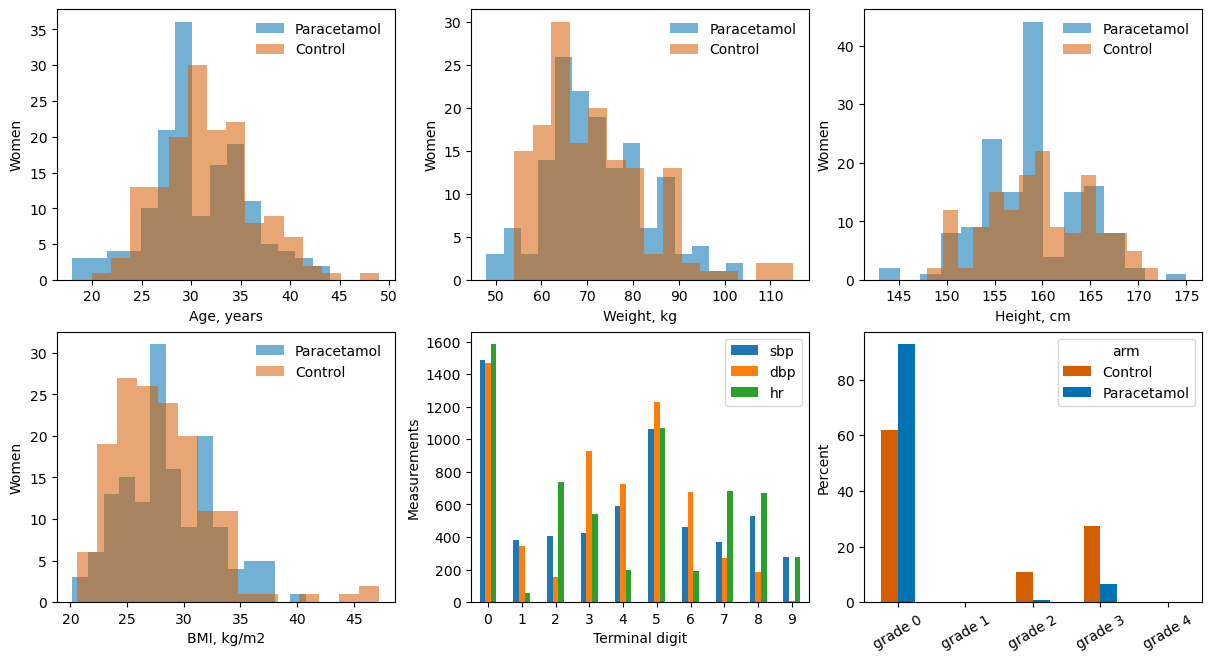

In [8]:
def heatmap(var, ax):
    matrix = sequence_matrix(var)
    member, keys, tally = exact_members(matrix)
    order = sorted(range(len(df)), key=lambda i: (-tally[keys[i]], keys[i]))
    image = ax.imshow(np.where(matrix[order] < 0, np.nan, matrix[order]), aspect="auto", cmap="viridis", interpolation="nearest")
    ax.axhline(member.sum() - 0.5, color="red", lw=1)
    ax.set(title=VITALS[var], xlabel="Time point")
    plt.colorbar(image, ax=ax, shrink=0.7)


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=600, bbox_inches="tight")
    plt.show()


fig, axes = plt.subplots(1, 3, figsize=(13, 6), constrained_layout=True)
for var, ax in zip(["sbp", "dbp", "hr"], axes):
    heatmap(var, ax)
axes[0].set_ylabel("Patients, ordered by size of identical group (above red line: duplicated)")
save(fig, "fig_integrity_heatmap")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), constrained_layout=True)
for ax, (var, label) in zip(axes.ravel(), [("age", "Age, years"), ("weight", "Weight, kg"), ("height", "Height, cm"), ("bmi", "BMI, kg/m2")]):
    for arm, colour in COLORS.items():
        ax.hist(df.loc[df.arm == arm, var].dropna(), bins=15, alpha=0.55, color=colour, label=arm)
    ax.set(xlabel=label, ylabel="Women")
    ax.legend(frameon=False)
digits.plot.bar(ax=axes[1, 1], rot=0)
axes[1, 1].set(xlabel="Terminal digit", ylabel="Measurements")
(grades.iloc[:, 1:].div(grades.iloc[:, 1:].sum(1), axis=0) * 100).T.plot.bar(ax=axes[1, 2], rot=30, color=[COLORS[a] for a in grades.index])
axes[1, 2].set(ylabel="Percent")
save(fig, "fig_eda")

In [9]:
def smd(a, b):
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled if pooled > 0 else 0.0


def describe_continuous(name, label):
    a, b = (df.loc[df.arm == arm, name].dropna() for arm in COLORS)
    fmt = lambda x: f"{x.mean():.1f} ({x.std():.1f}); {x.median():.1f} [{x.quantile(.25):.1f}, {x.quantile(.75):.1f}]; n={len(x)}"
    return {"characteristic": label, "Paracetamol": fmt(a), "Control": fmt(b), "SMD": round(smd(a, b), 2),
            "Shapiro P": f"{min(stats.shapiro(a).pvalue, stats.shapiro(b).pvalue):.3g}"}


def describe_binary(mask, label):
    k = mask.groupby(df.arm).sum()
    n = df.groupby("arm").size()
    p = k / n
    pooled = np.sqrt((p * (1 - p)).mean())
    return {"characteristic": label, **{a: f"{int(k[a])} ({100 * p[a]:.1f}%)" for a in COLORS},
            "SMD": round(float((p["Paracetamol"] - p["Control"]) / pooled), 2) if pooled > 0 else 0.0, "Shapiro P": ""}


text = df.diagnosis.str.lower()
df["previous_cs"] = text.str.contains(r"bekas\s*\+?\s*sc|bekas sc")
df["cpd"] = text.str.contains(r"cpd|cpp|panggul sempit")
df["malpresentation"] = text.str.contains(r"sunsang|sungsang|let su|lintang|letak muka|letak kaki")
gravidity = text.str.extract(r"^g\s*([0-9i]+)")[0].replace({"i": "1", "22": "2"})
df["gravidity"] = pd.to_numeric(gravidity, errors="coerce")
baseline = [describe_continuous(v, l) for v, l in [
    ("age", "Age, years"), ("weight", "Weight, kg"), ("height", "Height, cm"), ("bmi", "BMI, kg/m2"),
    ("sbp1", "Baseline systolic BP, mmHg"), ("dbp1", "Baseline diastolic BP, mmHg"), ("hr1", "Baseline heart rate"), ("spo21", "Baseline SpO2, %")]]
baseline += [describe_binary(m, l) for m, l in [
    (df.gravidity == 1, "Gravidity 1"), (df.gravidity == 2, "Gravidity 2"), (df.gravidity >= 3, "Gravidity 3 or more"),
    (df.gravidity.isna(), "Gravidity not recorded"), (df.previous_cs, "Previous caesarean delivery"),
    (df.cpd, "Cephalopelvic disproportion"), (df.malpresentation, "Malpresentation"),
    (df.protocol_ineligible, "Did not meet eligibility criteria")]]
section("Baseline characteristics")
print(keep("table1", pd.DataFrame(baseline)).to_string(index=False))


Baseline characteristics
                   characteristic                               Paracetamol                                   Control   SMD Shapiro P
                       Age, years      30.7 (5.1); 30.0 [27.2, 34.0]; n=150      31.6 (4.9); 31.0 [28.0, 34.0]; n=150 -0.17    0.0225
                       Weight, kg     72.1 (10.9); 71.0 [65.0, 78.0]; n=150     71.7 (12.0); 69.5 [63.0, 78.0]; n=150  0.04  2.28e-07
                       Height, cm  158.8 (5.2); 158.0 [155.0, 163.0]; n=149  159.7 (5.6); 160.0 [155.0, 164.8]; n=150 -0.17    0.0144
                       BMI, kg/m2      28.6 (4.1); 28.0 [25.7, 31.6]; n=149      28.1 (4.4); 27.5 [25.0, 30.4]; n=150  0.12  2.19e-08
       Baseline systolic BP, mmHg 118.7 (11.2); 118.0 [110.2, 124.8]; n=150 119.5 (14.9); 118.0 [109.2, 124.8]; n=150 -0.06  3.46e-07
      Baseline diastolic BP, mmHg      62.9 (9.1); 60.0 [55.0, 71.0]; n=150      59.0 (6.5); 56.0 [55.0, 60.0]; n=150  0.50  4.13e-13
              Baseline heart rate   

In [10]:
def two_by_two(frame, outcome):
    use = frame.dropna(subset=[outcome])
    g = use.groupby("treated")[outcome].agg(["sum", "size"]).reindex([1, 0])
    return int(g.loc[1, "sum"]), int(g.loc[1, "size"]), int(g.loc[0, "sum"]), int(g.loc[0, "size"])


def effects(a, n1, c, n0):
    table = np.array([[a, n1 - a], [c, n0 - c]])
    p1, p0 = a / n1, c / n0
    rr_lo, rr_hi = confint_proportions_2indep(a, n1, c, n0, compare="ratio", method="log")
    or_lo, or_hi = confint_proportions_2indep(a, n1, c, n0, compare="odds-ratio", method="logit")
    rd_lo, rd_hi = confint_proportions_2indep(c, n0, a, n1, compare="diff", method="newcomb")
    arr = p0 - p1
    ci1 = proportion_confint(a, n1, method="wilson")
    ci0 = proportion_confint(c, n0, method="wilson")
    chi = stats.chi2_contingency(table, correction=False)
    return {"paracetamol": f"{a}/{n1} ({100 * p1:.1f}%; {100 * ci1[0]:.1f} to {100 * ci1[1]:.1f})",
            "control": f"{c}/{n0} ({100 * p0:.1f}%; {100 * ci0[0]:.1f} to {100 * ci0[1]:.1f})",
            "RR (95% CI)": f"{p1 / p0:.2f} ({rr_lo:.2f} to {rr_hi:.2f})",
            "ARR % (95% CI)": f"{100 * arr:.1f} ({100 * rd_lo:.1f} to {100 * rd_hi:.1f})",
            "NNT (95% CI)": f"{1 / arr:.1f} ({1 / rd_hi:.1f} to {1 / rd_lo:.1f})" if rd_lo > 0 else "not defined",
            "OR (95% CI)": f"{(a * (n0 - c)) / ((n1 - a) * c):.2f} ({or_lo:.2f} to {or_hi:.2f})",
            "chi-square": round(chi.statistic, 1), "P chi-square": f"{chi.pvalue:.2e}",
            "P Fisher": f"{stats.fisher_exact(table).pvalue:.2e}"}


def scenario(frame, value_treated, value_control):
    filled = frame.copy()
    fill = pd.Series(np.where(filled.treated == 1, value_treated, value_control), index=filled.index)
    filled["shiver"] = filled.shiver.fillna(fill)
    return filled


analyses = {
    "Primary: all recorded women with an outcome": df,
    "Missing outcome counted as no shivering": scenario(df, 0, 0),
    "Missing outcome counted as shivering": scenario(df, 1, 1),
    "Excluding women not meeting eligibility criteria": df[~df.protocol_ineligible],
    "Also excluding fetal distress or PTM notes (post hoc)": df[~df.protocol_ineligible & ~df.diagnosis.str.lower().str.contains(r"gawat|vital|\bptm\b")],
}
primary = pd.DataFrame({k: effects(*two_by_two(v, "shiver")) for k, v in analyses.items()})
section("Primary outcome: any shivering (unverified)" if not DATA_VERIFIED else "Primary outcome: any shivering")
print(keep("primary_outcome", primary.T.reset_index(names="analysis").assign(status=STATUS)).set_index("analysis").T.to_string())
print("\nA per-protocol analysis cannot be run because adherence to dose, timing and protocol steps was not recorded.")


Primary outcome: any shivering (unverified)
analysis       Primary: all recorded women with an outcome Missing outcome counted as no shivering Missing outcome counted as shivering Excluding women not meeting eligibility criteria Also excluding fetal distress or PTM notes (post hoc)
paracetamol                     11/150 (7.3%; 4.1 to 12.7)              11/150 (7.3%; 4.1 to 12.7)           11/150 (7.3%; 4.1 to 12.7)                       10/127 (7.9%; 4.3 to 13.9)                            10/125 (8.0%; 4.4 to 14.1)
control                       57/149 (38.3%; 30.8 to 46.3)            57/150 (38.0%; 30.6 to 46.0)         58/150 (38.7%; 31.2 to 46.7)                     49/133 (36.8%; 29.1 to 45.3)                          45/127 (35.4%; 27.7 to 44.1)
RR (95% CI)                            0.19 (0.10 to 0.35)                     0.19 (0.11 to 0.35)                  0.19 (0.10 to 0.35)                              0.21 (0.11 to 0.40)                                   0.23 (0.12 to 0.43)

In [11]:
def fragility(a, n1, c, n0):
    flips = 0
    while a < n1 and stats.fisher_exact([[a, n1 - a], [c, n0 - c]]).pvalue < 0.05:
        a, flips = a + 1, flips + 1
    return flips


def poisson_rr(formula, frame):
    terms = [t.strip() for t in formula.split("~")[1].split("+")]
    use = frame.dropna(subset=["shiver"] + terms)
    fit = smf.glm(formula, use, family=sm.families.Poisson()).fit(cov_type="HC1")
    lo, hi = np.exp(fit.conf_int().loc["treated"])
    return {"model": formula, "n": len(use), "RR": round(np.exp(fit.params["treated"]), 3), "low": round(lo, 3),
            "high": round(hi, 3), "P": f"{fit.pvalues['treated']:.2e}"}


a, n1, c, n0 = two_by_two(df, "shiver")
section("Robustness")
adjusted = pd.DataFrame([poisson_rr(f, df) for f in [
    "shiver ~ treated", "shiver ~ treated + age + bmi", "shiver ~ treated + age + bmi + previous_cs + sbp1 + hr1"]])
print(keep("adjusted_models", adjusted.assign(status=STATUS)).to_string(index=False))
post1 = RNG.beta(1 + a, 1 + n1 - a, CFG.draws)
post0 = RNG.beta(1 + c, 1 + n0 - c, CFG.draws)
bayes = pd.Series({"posterior median RR": np.median(post1 / post0),
                   "95% credible low": np.quantile(post1 / post0, .025), "95% credible high": np.quantile(post1 / post0, .975),
                   "P(RR < 1)": np.mean(post1 < post0), "P(ARR > 15 points)": np.mean(post0 - post1 > .15),
                   "fragility index": fragility(a, n1, c, n0)})
print(keep("bayes_fragility", bayes.rename("value").to_frame().assign(status=STATUS)).to_string())

subgroups = []
for label, flag in [("Age 35 or older", df.age >= 35), ("BMI 30 or higher", (df.bmi >= 30).astype(float).where(df.bmi.notna())), ("Previous caesarean", df.previous_cs)]:
    work = df.assign(sub=flag.astype(float)).dropna(subset=["shiver", "sub"])
    fit = smf.glm("shiver ~ treated * sub", work, family=sm.families.Poisson()).fit(cov_type="HC1")
    for level in (0, 1):
        res = effects(*two_by_two(work[work["sub"] == level], "shiver"))
        subgroups.append({"subgroup": label, "present": bool(level), "RR (95% CI)": res["RR (95% CI)"],
                          "interaction P": round(fit.pvalues["treated:sub"], 3)})
print(keep("subgroups_exploratory", pd.DataFrame(subgroups).assign(status=STATUS)).to_string(index=False))


Robustness
                                                  model   n    RR   low  high        P     status
                                       shiver ~ treated 299 0.192 0.105 0.351 8.45e-08 UNVERIFIED
                           shiver ~ treated + age + bmi 298 0.194 0.106 0.355 9.85e-08 UNVERIFIED
shiver ~ treated + age + bmi + previous_cs + sbp1 + hr1 298 0.193 0.105 0.353 1.01e-07 UNVERIFIED
                         value      status
posterior median RR   0.201467  UNVERIFIED
95% credible low      0.106068  UNVERIFIED
95% credible high     0.345731  UNVERIFIED
P(RR < 1)             1.000000  UNVERIFIED
P(ARR > 15 points)    0.999750  UNVERIFIED
fragility index      31.000000  UNVERIFIED
          subgroup  present         RR (95% CI)  interaction P     status
   Age 35 or older    False 0.22 (0.11 to 0.43)          0.502 UNVERIFIED
   Age 35 or older     True 0.13 (0.03 to 0.51)          0.502 UNVERIFIED
  BMI 30 or higher    False 0.15 (0.07 to 0.35)          0.320 UNVERIFIED

In [12]:
section("Secondary outcomes: severity")
x, y = (df.loc[df.arm == arm, "wrench"].dropna() for arm in COLORS)
mw = stats.mannwhitneyu(x, y, alternative="two-sided")
delta = 2 * mw.statistic / (len(x) * len(y)) - 1
table3x2 = pd.crosstab(df.arm, df.wrench)
print(f"Mann-Whitney P {mw.pvalue:.2e}  Cliff delta {delta:.3f}  probabilistic index {mw.statistic / (len(x) * len(y)):.3f}")
print(f"chi-square for observed grades P {stats.chi2_contingency(table3x2).pvalue:.2e}")
severity = pd.DataFrame({
    "grade 3 or 4, all women": effects(*two_by_two(df, "severe")),
    "grade 3 or 4 among shiverers (post-randomisation subset)": effects(*two_by_two(df[df.shiver == 1], "severe"))})
print(keep("severity", severity.T.reset_index(names="analysis").assign(status=STATUS)).set_index("analysis").T.to_string())


Secondary outcomes: severity
Mann-Whitney P 5.04e-10  Cliff delta -0.304  probabilistic index 0.348
chi-square for observed grades P 9.09e-10
analysis             grade 3 or 4, all women grade 3 or 4 among shiverers (post-randomisation subset)
paracetamol       10/150 (6.7%; 3.7 to 11.8)                              10/11 (90.9%; 62.3 to 98.4)
control         41/149 (27.5%; 21.0 to 35.2)                              41/57 (71.9%; 59.2 to 81.9)
RR (95% CI)              0.24 (0.13 to 0.47)                                      1.26 (0.99 to 1.62)
ARR % (95% CI)           20.9 (12.5 to 29.1)                                    -19.0 (-33.8 to 11.4)
NNT (95% CI)                4.8 (3.4 to 8.0)                                              not defined
OR (95% CI)              0.19 (0.09 to 0.39)                                     3.90 (0.46 to 33.01)
chi-square                              23.0                                                      1.8
P chi-square                        1.65e

In [13]:
def long_form(var):
    wide = df[["study_id", "arm", "treated"] + cols(var)]
    out = wide.melt(["study_id", "arm", "treated"], var_name="time", value_name="value").dropna()
    out["time"] = out.time.str[len(var):].astype(int)
    out["baseline"] = out.study_id.map(df.set_index("study_id")[f"{var}1"])
    return out


section("Haemodynamics (series failed integrity screening, shown for audit only)")
mixed = []
for var in ["sbp", "dbp", "hr"]:
    data = long_form(var)
    for label, formula, frame in [("group + time", "value ~ treated + C(time)", data),
                                  ("baseline adjusted, T2 to T20", "value ~ treated + baseline + C(time)", data[data.time > 1])]:
        fit = smf.mixedlm(formula, frame, groups=frame.study_id).fit(reml=True)
        lo, hi = fit.conf_int().loc["treated"]
        re_var = float(fit.cov_re.iloc[0, 0])
        mixed.append({"variable": VITALS[var], "model": label, "difference": round(fit.params["treated"], 2), "low": round(lo, 2),
                      "high": round(hi, 2), "P": f"{fit.pvalues['treated']:.3g}",
                      "ICC": round(re_var / (re_var + fit.scale), 2), "status": STATUS})
    ordered = data[data.time > 1].sort_values(["study_id", "time"])
    structure = sm.cov_struct.Autoregressive(grid=True)
    gee = smf.gee("value ~ treated + baseline + C(time)", "study_id", ordered, time=ordered.time, cov_struct=structure).fit()
    lo, hi = gee.conf_int().loc["treated"]
    mixed.append({"variable": VITALS[var], "model": "GEE AR(1), baseline adjusted, T2 to T20", "difference": round(gee.params["treated"], 2),
                  "low": round(lo, 2), "high": round(hi, 2), "P": f"{gee.pvalues['treated']:.3g}",
                  "ICC": np.nan, "status": STATUS})
print(keep("repeated_measures", pd.DataFrame(mixed)).to_string(index=False))

sbp = df[cols("sbp")]
events = {
    "SBP fall of more than 20% from baseline": sbp.iloc[:, 1:].lt(0.8 * df.sbp1, axis=0).any(axis=1),
    "SBP below 90 mmHg": sbp.lt(90).any(axis=1),
    "Heart rate below 60": df[cols("hr")].lt(60).any(axis=1),
    "SpO2 below 95%": df[cols("spo2")].lt(95).any(axis=1),
}
rows = []
for label, mask in events.items():
    k = mask.groupby(df.arm).sum()
    n = df.groupby("arm").size()
    p = stats.fisher_exact([[k[a], n[a] - k[a]] for a in COLORS]).pvalue
    rows.append({"event": label, **{a: f"{int(k[a])}/{n[a]}" for a in COLORS}, "P Fisher": round(p, 3)})
print(keep("haemodynamic_events", pd.DataFrame(rows).assign(status=STATUS)).to_string(index=False))

removed = long_form("sbp").merge(errors.assign(time=errors.variable.str[3:].astype(int))[["study_id", "time"]], how="left", indicator=True)
sensitivity = []
for label, frame in [("four-digit entries corrected", removed), ("four-digit entries set to missing", removed[removed["_merge"] == "left_only"])]:
    fit = smf.mixedlm("value ~ treated + C(time)", frame, groups=frame.study_id).fit(reml=True)
    low, high = fit.conf_int().loc["treated"]
    sensitivity.append({"systolic data": label, "difference": round(fit.params["treated"], 2), "low": round(low, 2), "high": round(high, 2), "status": STATUS})
print(keep("correction_sensitivity", pd.DataFrame(sensitivity)).to_string(index=False))

pointwise = pd.DataFrame({f"{v} difference": df[df.treated == 1][cols(v)].mean().to_numpy()
                          - df[df.treated == 0][cols(v)].mean().to_numpy() for v in ["sbp", "dbp", "hr"]},
                         index=[f"T{t}" for t in range(1, CFG.n_time + 1)])
print("\nmean difference, paracetamol minus control, at each time point (descriptive)")
print(keep("pointwise_differences", pointwise.round(1).assign(status=STATUS)).to_string())

Output withheld in the public version because it shows participant level or unreported haemodynamic results.


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, var in zip(axes, ["sbp", "dbp", "hr"]):
    for arm, colour in COLORS.items():
        values = df.loc[df.arm == arm, cols(var)]
        mean, half = values.mean(), 1.96 * values.sem()
        t = np.arange(1, CFG.n_time + 1)
        ax.plot(t, mean, color=colour, marker="o", ms=3, label=arm)
        ax.fill_between(t, mean - half, mean + half, color=colour, alpha=0.2)
    ax.set(xlabel="Time point", ylabel=VITALS[var])
    ax.legend(frameon=False)
fig.suptitle("UNVERIFIED haemodynamic series. Not for publication.", color="red")
save(fig, "fig_haemodynamics_audit")

Output withheld in the public version because it shows participant level or unreported haemodynamic results.


In [15]:
section("Design evaluation")
p_control, p_treated = 0.35, 0.20
pbar = (p_control + p_treated) / 2
za, zb = stats.norm.ppf(0.975), stats.norm.ppf(0.80)
n_group = (za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p_control * (1 - p_control) + p_treated * (1 - p_treated))) ** 2 / (p_control - p_treated) ** 2
h = 2 * np.arcsin(np.sqrt(p_control)) - 2 * np.arcsin(np.sqrt(p_treated))
arcsine = NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.80)
design = pd.Series({"n per group, pooled-variance formula": np.ceil(n_group), "n per group, arcsine method": np.ceil(arcsine),
                    "with 8% attrition": np.ceil(np.ceil(n_group) / 0.92), "analysed with outcome": int(df.shiver.notna().sum())})
print(keep("sample_size", design.rename("value").to_frame()).to_string())

with pd.ExcelWriter(OUT / "analysis_results.xlsx") as writer:
    for name, table in TABLES.items():
        table.to_excel(writer, sheet_name=name[:31], index=name in {"completeness", "eligibility_counts", "terminal_digits", "wrench_grades", "bayes_fragility", "sample_size", "pointwise_differences"})
df.drop(columns=["diagnosis", "excel_row", "no"]).to_csv(OUT / "analysis_dataset_pseudonymised.csv", index=False)
section("Run complete")
print(f"integrity gate passed: {DATA_VERIFIED}")
print(sorted(p.name for p in OUT.iterdir()))


Design evaluation
                                      value
n per group, pooled-variance formula  138.0
n per group, arcsine method           137.0
with 8% attrition                     150.0
analysed with outcome                 299.0



Run complete
integrity gate passed: False
['analysis_dataset_pseudonymised.csv', 'analysis_results.xlsx', 'fig_eda.png', 'fig_haemodynamics_audit.png', 'fig_integrity_heatmap.png']
